# Bab 6 — Research Implementation with Python

Notebook pendamping Bab 6 Level 7. Jalankan sel dari atas ke bawah, dan **jalankan skrip atau notebook Bab 2, 4, dan 5 lebih dulu**. Bagian A sampai L mengikuti halaman bab dan menjalankan seluruh protokol (156 eksekusi, sekitar setengah menit). Bagian **Praktik** berisi kegiatan yang tidak ada di halaman: menguji pemeriksaan hash, mencatat analisis eksploratori secara terpisah, dan memeriksa keterulangan.

Dataset: Breast Cancer Wisconsin (Diagnostic), UCI, CC BY 4.0. Bukan alat diagnosis. Gambar tampil langsung di notebook.

## Learning Objectives

Setelah mengerjakan notebook ini, kamu mampu:

- Membuktikan bahwa pemeriksaan hash protokol menolak protokol yang berubah.
- Menjalankan analisis eksploratori tanpa mengubah hasil utama dan mencatatnya terpisah.
- Memeriksa keterulangan hasil dengan membandingkan perhitungan ulang dengan berkas tersimpan.

## Langkah 0: Pindah ke folder utama proyek

In [1]:
import os
import sys
from pathlib import Path

if not Path("data").exists() and not Path("examples").exists():
    os.chdir("../..")

ROOT = Path.cwd()
# alat bantu bersama Level 7 (examples/level-7/_research.py)
sys.path.insert(0, str(Path("examples/level-7").resolve()))

## Bagian A: Siapkan alat dan periksa protokol terkunci

In [2]:
import hashlib
import json
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler, StandardScaler

import _research as rs

RESULTS = rs.RESULTS_DIR
SEED = 42


def protocol_hash(p):
    return hashlib.sha256(json.dumps(p, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest()


protocol = json.loads((RESULTS / "05_protocol.json").read_text(encoding="utf-8"))
locked = (RESULTS / "05_protocol.sha256").read_text(encoding="utf-8").strip()
if protocol_hash(protocol) != locked:
    raise SystemExit("Protokol berubah sejak dikunci. Eksperimen tidak dijalankan.")
print("Protokol terkunci terverifikasi:", locked[:16], "...")

fits = {"RQ1": 0, "RQ2": 0, "RQ3": 0, "K": 0}   # penghitung eksekusi, dicocokkan dengan protokol di akhir
clarifications = []                               # hal yang belum ditetapkan protokol dan diputuskan saat implementasi

Protokol terkunci terverifikasi: c65be407e00ab39b ...


## Bagian B: Memuat dataset penelitian

In [3]:
frame = pd.read_csv(RESULTS / "04_research_dataset.csv")
y = frame.pop("diagnosis")
X = frame
fingerprint_ok = rs.dataset_fingerprint(X) == protocol["dataset"]["sidik_jari"]
print("Dataset:", X.shape, "| diagnosis:", y.value_counts().to_dict())
print("Sidik jari cocok dengan protokol:", fingerprint_ok)
if not fingerprint_ok:
    raise SystemExit("Sidik jari data berbeda dari protokol.")

Dataset: (569, 30) | diagnosis: {'benign': 357, 'malignant': 212}
Sidik jari cocok dengan protokol: True


## Bagian C: Eksplorasi data singkat

In [4]:
std = X.std().sort_values()
print("Simpangan baku terkecil :", std.index[0], round(float(std.iloc[0]), 5))
print("Simpangan baku terbesar :", std.index[-1], round(float(std.iloc[-1]), 2))
print("Rasio terbesar/terkecil :", f"{float(std.iloc[-1] / std.iloc[0]):.3g}")
print("Proporsi malignant      :", round(float((y == "malignant").mean()), 3))
print(X[["mean radius", "mean area", "mean smoothness"]].describe().loc[["min", "mean", "max"]].round(3).to_string())

Simpangan baku terkecil : fractal dimension error 0.00265
Simpangan baku terbesar : worst area 569.36
Rasio terbesar/terkecil : 2.15e+05
Proporsi malignant      : 0.373
      mean radius  mean area  mean smoothness
min         6.981    143.500            0.053
mean       14.127    654.889            0.096
max        28.110   2501.000            0.163


## Bagian D: Praproses sesuai protokol

In [5]:
X_raw = X.to_numpy(dtype=float)
X_base = StandardScaler().fit_transform(X_raw)       # baseline protokol
X_minmax = MinMaxScaler().fit_transform(X_raw)
n = X_base.shape[0]
print("Baseline: rata-rata kolom ~", round(float(X_base.mean()), 6), "| simpangan baku ~", round(float(X_base.std()), 3))

Baseline: rata-rata kolom ~ -0.0 | simpangan baku ~ 1.0


## Bagian E: Fungsi metrik

In [6]:
def internal_metrics(Xs, labels):
    """Silhouette, Davies-Bouldin, Calinski-Harabasz di ruang Xs. Titik noise (-1) dikeluarkan."""
    mask = labels != -1
    if len(set(labels[mask])) < 2:
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {
        "silhouette": silhouette_score(Xs[mask], labels[mask]),
        "davies_bouldin": davies_bouldin_score(Xs[mask], labels[mask]),
        "calinski_harabasz": calinski_harabasz_score(Xs[mask], labels[mask]),
    }


def external_metrics(truth, labels):
    """ARI dan NMI terhadap diagnosis. Titik noise diperlakukan sebagai satu kelompok tambahan."""
    return {"ari_vs_diagnosis": adjusted_rand_score(truth, labels), "nmi_vs_diagnosis": normalized_mutual_info_score(truth, labels)}


clarifications.append({"id": "C1", "hal": "metrik internal DBSCAN", "keputusan": "titik noise dikeluarkan saat menghitung Silhouette, Davies-Bouldin, dan Calinski-Harabasz", "alasan": "metrik internal membutuhkan kelompok; noise bukan kelompok"})
clarifications.append({"id": "C2", "hal": "noise pada validasi eksternal", "keputusan": "label noise (-1) diperlakukan sebagai satu kelompok tambahan pada ARI dan NMI", "alasan": "agar semua titik ikut dihitung dan hasil tidak tampak lebih baik karena noise dibuang"})

## Bagian F: RQ1 kestabilan

In [7]:
km = protocol["algoritma"]["KMeans"]
plan1 = protocol["analisis"]["RQ1"]["ulangan"]

seed_labels = []
for s in range(plan1["seed"]):
    seed_labels.append(KMeans(n_clusters=km["n_clusters"], n_init=km["n_init"], random_state=s).fit_predict(X_base))
    fits["RQ1"] += 1
pair_ari = np.array([adjusted_rand_score(a, b) for a, b in combinations(seed_labels, 2)])

# Pengelompokan acuan (data penuh, seed dasar) = juga baseline RQ3; dihitung di bagian RQ3.
reference = KMeans(n_clusters=km["n_clusters"], n_init=km["n_init"], random_state=SEED).fit_predict(X_base)

rng = np.random.default_rng(SEED)
size = int(round(plan1["fraksi_subsampel"] * n))
sub_ari = []
for _ in range(plan1["subsampel"]):
    idx = np.sort(rng.choice(n, size=size, replace=False))
    X_sub = StandardScaler().fit_transform(X_raw[idx])      # praproses diulang pada subsampel
    labels_sub = KMeans(n_clusters=km["n_clusters"], n_init=km["n_init"], random_state=SEED).fit_predict(X_sub)
    fits["RQ1"] += 1
    sub_ari.append(adjusted_rand_score(reference[idx], labels_sub))
sub_ari = np.array(sub_ari)

rq1 = {
    "stab_seed_mean": float(pair_ari.mean()), "stab_seed_min": float(pair_ari.min()), "pasangan": int(len(pair_ari)),
    "stab_sub_mean": float(sub_ari.mean()), "stab_sub_min": float(sub_ari.min()), "stab_sub_max": float(sub_ari.max()),
    "ukuran_subsampel": size,
}
for key, value in rq1.items():
    print(f"{key:16s}: {round(value, 4) if isinstance(value, float) else value}")
clarifications.append({"id": "C3", "hal": "subsampel pada RQ1", "keputusan": "StandardScaler dihitung ulang pada tiap subsampel; K-Means memakai seed 42; subsampel diambil tanpa pengembalian dengan generator seed 42", "alasan": "seluruh alur praproses diulang agar sesuai praktik nyata; protokol hanya menyebut fraksi 0,8"})

stab_seed_mean  : 0.9814
stab_seed_min   : 0.9647
pasangan        : 190
stab_sub_mean   : 0.9638
stab_sub_min    : 0.8709
stab_sub_max    : 1.0
ukuran_subsampel: 455


## Bagian G: RQ2 kepekaan skala

In [8]:
levels = {
    "StandardScaler (baseline)": X_base,
    "tanpa skala": X_raw,
    "MinMaxScaler": X_minmax,
}
assert list(levels) == protocol["analisis"]["RQ2"]["level"], "level skala harus sama dengan protokol"
threshold = protocol["aturan_keputusan"]["ambang_praktis_sama_ARI"]
rows = []
ari_by_level = {}
for name, Xs in levels.items():
    aris = []
    for s in range(protocol["analisis"]["RQ2"]["ulangan"]["seed"]):
        labels = KMeans(n_clusters=km["n_clusters"], n_init=km["n_init"], random_state=s).fit_predict(Xs)
        fits["RQ2"] += 1
        aris.append(adjusted_rand_score(reference, labels))
    aris = np.array(aris)
    ari_by_level[name] = aris
    rows.append({"perlakuan": name, "ari_mean": aris.mean(), "ari_min": aris.min(), "ari_max": aris.max(), f"proporsi_ari>={threshold}": float((aris >= threshold).mean())})
rq2 = pd.DataFrame(rows).set_index("perlakuan")
print(rq2.round(3).to_string())

                           ari_mean  ari_min  ari_max  proporsi_ari>=0.95
perlakuan                                                                
StandardScaler (baseline)     0.982    0.965    1.000                 1.0
tanpa skala                   0.496    0.496    0.496                 0.0
MinMaxScaler                  0.896    0.896    0.896                 0.0


## Bagian H: RQ3 algoritma dan validasi eksternal

In [9]:
cfg = protocol["algoritma"]
final = {}
final["KMeans"] = reference                                   # baseline, seed dasar (dihitung di RQ1)
fits["RQ3"] += 1
final["Agglomerative"] = AgglomerativeClustering(n_clusters=cfg["Agglomerative"]["n_clusters"], linkage=cfg["Agglomerative"]["linkage"]).fit_predict(X_base)
fits["RQ3"] += 1
final["GMM"] = GaussianMixture(n_components=cfg["GMM"]["n_components"], covariance_type=cfg["GMM"]["covariance_type"], n_init=cfg["GMM"]["n_init"], random_state=SEED).fit_predict(X_base)
fits["RQ3"] += 1

# DBSCAN: grid tanpa label, aturan seleksi dari protokol
db = cfg["DBSCAN"]
grid_rows = []
grid_labels = {}
for k in db["min_samples"]:
    kth = NearestNeighbors(n_neighbors=k).fit(X_base).kneighbors(X_base)[0][:, -1]
    for q in db["eps_kuantil_jarak_tetangga"]:
        eps = float(np.quantile(kth, q))
        labels = DBSCAN(eps=eps, min_samples=k).fit_predict(X_base)
        fits["RQ3"] += 1
        n_clusters = len(set(labels) - {-1})
        noise = float((labels == -1).mean())
        sil = internal_metrics(X_base, labels)["silhouette"]
        valid = bool(n_clusters >= 2 and noise <= 0.10)
        grid_rows.append({"min_samples": k, "kuantil": q, "eps": eps, "kelompok": n_clusters, "noise_persen": 100 * noise, "silhouette": sil, "valid": valid})
        grid_labels[(k, q)] = labels
dbscan_grid = pd.DataFrame(grid_rows)
print(dbscan_grid.round(3).to_string(index=False))

valid_grid = dbscan_grid[dbscan_grid["valid"]]
selected = None
if len(valid_grid):
    best = valid_grid.sort_values("silhouette", ascending=False).iloc[0]
    selected = (int(best["min_samples"]), float(best["kuantil"]))
    final["DBSCAN"] = grid_labels[selected]
    print("DBSCAN terpilih:", selected)
else:
    print("DBSCAN: tidak ada konfigurasi valid (minimal 2 kelompok dan noise paling banyak 10 persen). Aturan tidak dilonggarkan.")

rows = []
for name, labels in final.items():
    rows.append({"algoritma": name, "kelompok": len(set(labels) - {-1}), "noise": int((labels == -1).sum()),
                 **internal_metrics(X_base, labels), **external_metrics(y, labels)})
rq3 = pd.DataFrame(rows).set_index("algoritma")
print(rq3.round(3).to_string())
clarifications.append({"id": "C4", "hal": "baseline acuan", "keputusan": "baseline acuan RQ1 dan RQ2 adalah K-Means StandardScaler dengan seed 42, yang sama dengan K-Means pada RQ3 (dihitung sekali)", "alasan": "protokol menyebut random_state dasar 42 tetapi tidak menyebut dari mana acuan diambil"})
clarifications.append({"id": "C5", "hal": "jarak ke tetangga ke-k pada DBSCAN", "keputusan": "jarak ke tetangga ke-k dihitung termasuk titik itu sendiri sebagai tetangga pertama", "alasan": "konsisten dengan cara scikit-learn menghitung min_samples (titik itu sendiri ikut dihitung)"})

 min_samples  kuantil   eps  kelompok  noise_persen  silhouette  valid
           5     0.80 3.505         1        13.181         NaN  False
           5     0.85 3.786         1        10.721         NaN  False
           5     0.90 4.325         1         6.678         NaN  False
           5     0.95 5.374         1         3.339         NaN  False
          10     0.80 3.898         1        10.545         NaN  False
          10     0.85 4.177         1         7.909         NaN  False
          10     0.90 4.784         1         4.921         NaN  False
          10     0.95 5.974         1         2.285         NaN  False
DBSCAN: tidak ada konfigurasi valid (minimal 2 kelompok dan noise paling banyak 10 persen). Aturan tidak dilonggarkan.
               kelompok  noise  silhouette  davies_bouldin  calinski_harabasz  ari_vs_diagnosis  nmi_vs_diagnosis
algoritma                                                                                                        
KMeans        

## Bagian I: Sensitivitas K

In [10]:
plan_k = protocol["analisis"]["sensitivitas_K"]
k_rows = []
for k in plan_k["level"]:
    models = {
        "KMeans": KMeans(n_clusters=k, n_init=km["n_init"], random_state=SEED),
        "Agglomerative": AgglomerativeClustering(n_clusters=k, linkage=cfg["Agglomerative"]["linkage"]),
        "GMM": GaussianMixture(n_components=k, covariance_type=cfg["GMM"]["covariance_type"], n_init=cfg["GMM"]["n_init"], random_state=SEED),
    }
    for name, model in models.items():
        labels = model.fit_predict(X_base)
        fits["K"] += 1
        k_rows.append({"k": k, "algoritma": name, "silhouette": silhouette_score(X_base, labels)})
k_table = pd.DataFrame(k_rows).pivot(index="k", columns="algoritma", values="silhouette")
print(k_table.round(3).to_string())
print("K dengan Silhouette tertinggi per algoritma:", {c: int(k_table[c].idxmax()) for c in k_table.columns})

algoritma  Agglomerative    GMM  KMeans
k                                      
2                  0.339  0.314   0.343
3                  0.330  0.274   0.314
4                  0.298  0.128   0.283
5                  0.243  0.126   0.158
6                  0.120  0.116   0.160
K dengan Silhouette tertinggi per algoritma: {'Agglomerative': 2, 'GMM': 2, 'KMeans': 2}


## Bagian J: Profil kelompok

In [11]:
z = pd.DataFrame(X_base, columns=X.columns)
cluster = pd.Series(reference, name="kelompok")
profile = z.groupby(cluster).mean().T
profile.columns = [f"kelompok_{c}" for c in profile.columns]
profile["selisih"] = profile.iloc[:, 1] - profile.iloc[:, 0]
top = profile["selisih"].abs().sort_values(ascending=False).head(6).index
print("Ukuran kelompok:", cluster.value_counts().sort_index().to_dict())
print("Enam fitur dengan selisih z-score terbesar antar kelompok:")
print(profile.loc[top].round(2).to_string())
crosstab = pd.crosstab(cluster, y)
print("Tabulasi silang kelompok x diagnosis (jumlah):")
print(crosstab.to_string())
print("Proporsi malignant per kelompok:", (crosstab["malignant"] / crosstab.sum(axis=1)).round(3).to_dict())

Ukuran kelompok: {0: 375, 1: 194}
Enam fitur dengan selisih z-score terbesar antar kelompok:
                      kelompok_0  kelompok_1  selisih
mean concave points        -0.59        1.13     1.72
worst concave points       -0.58        1.12     1.70
mean concavity             -0.58        1.12     1.70
worst concavity            -0.54        1.04     1.57
worst perimeter            -0.53        1.03     1.56
mean compactness           -0.53        1.02     1.54
Tabulasi silang kelompok x diagnosis (jumlah):
diagnosis  benign  malignant
kelompok                    
0             339         36
1              18        176
Proporsi malignant per kelompok: {0: 0.096, 1: 0.907}


## Bagian K: Visualisasi

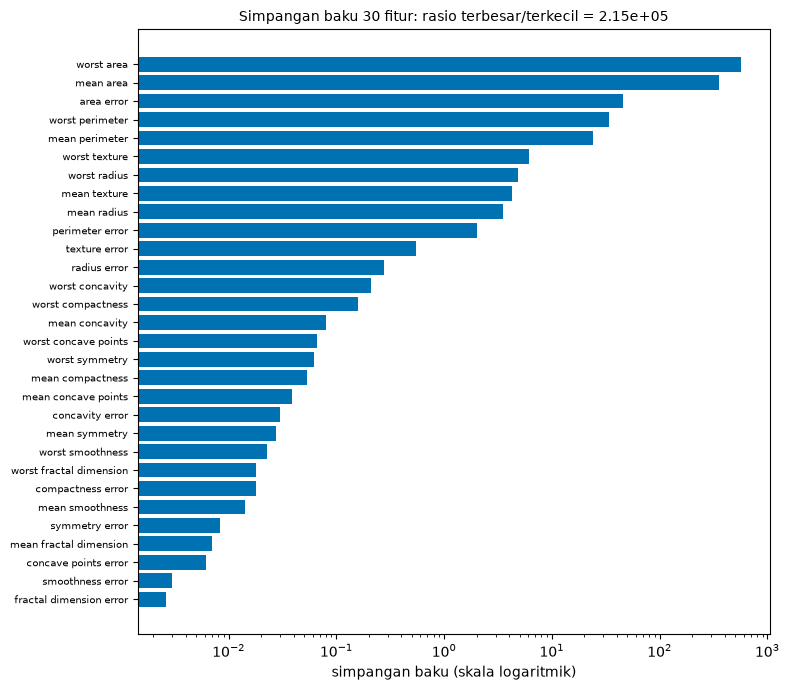

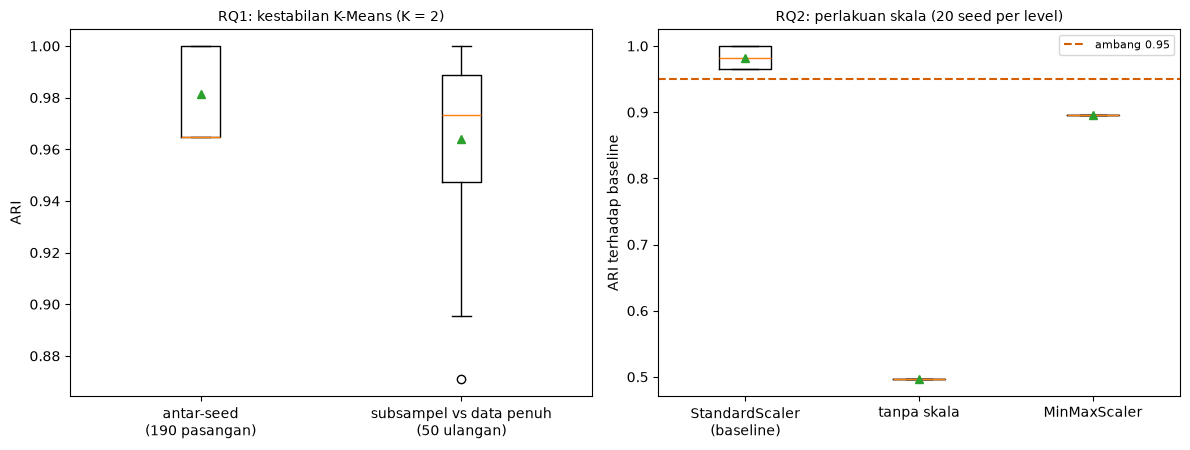

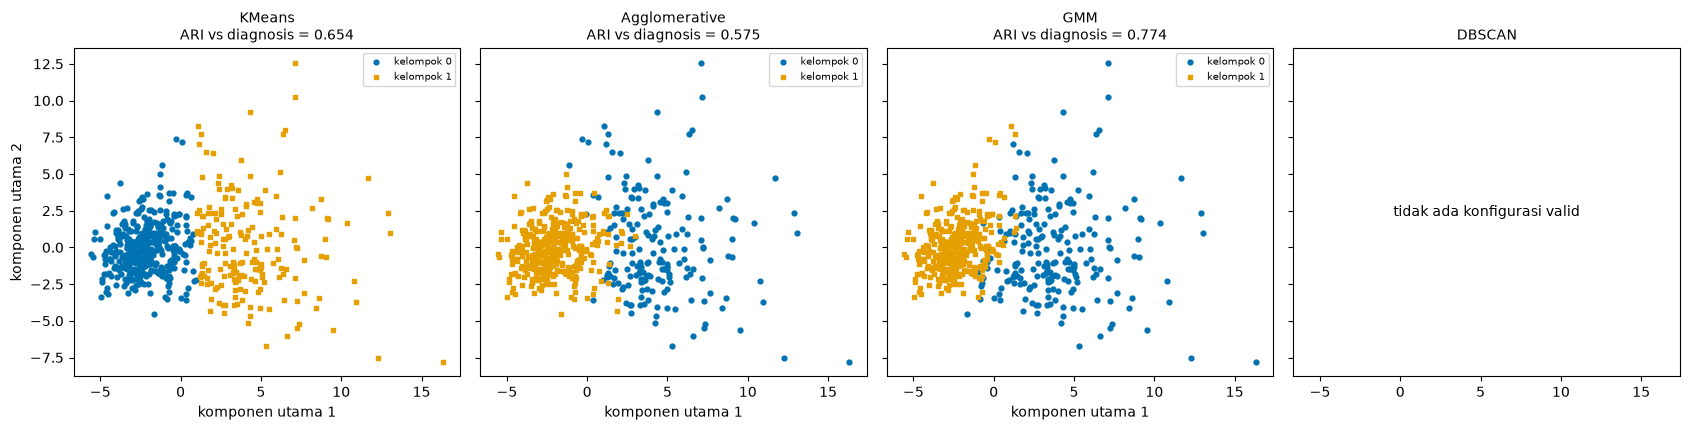

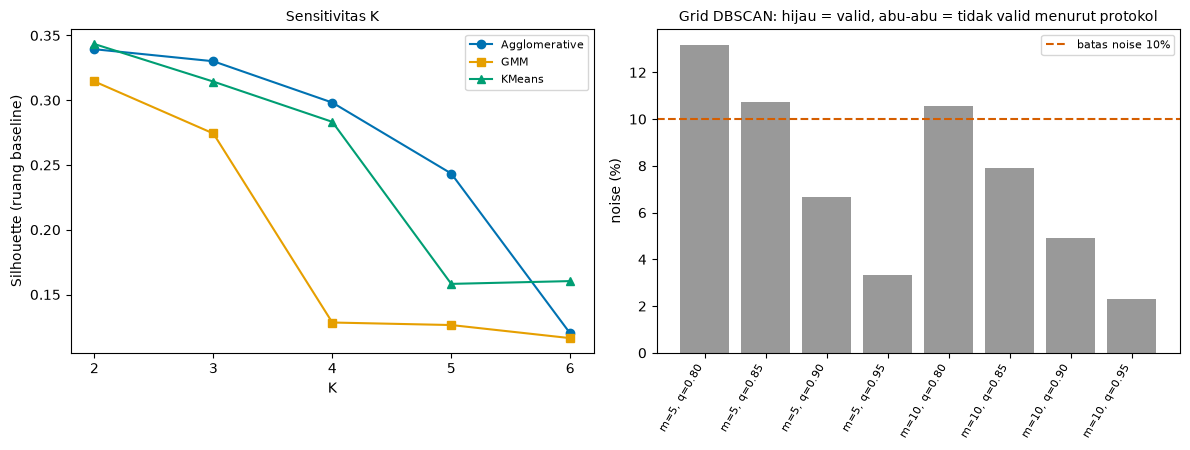

In [12]:
palette = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
markers = ["o", "s", "^", "D"]

# Gambar 1: skala fitur
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(std.index, std.values, color="#0072B2")
ax.set_xscale("log")
ax.set_xlabel("simpangan baku (skala logaritmik)")
ax.set_title(f"Simpangan baku 30 fitur: rasio terbesar/terkecil = {float(std.iloc[-1] / std.iloc[0]):.3g}", fontsize=10)
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

# Gambar 2: kestabilan (RQ1) dan kepekaan skala (RQ2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].boxplot([pair_ari, sub_ari], tick_labels=["antar-seed\n(190 pasangan)", "subsampel vs data penuh\n(50 ulangan)"], showmeans=True)
axes[0].set_ylabel("ARI")
axes[0].set_title("RQ1: kestabilan K-Means (K = 2)", fontsize=10)
axes[1].boxplot(list(ari_by_level.values()), tick_labels=[name.replace(" (baseline)", "\n(baseline)") for name in ari_by_level], showmeans=True)
axes[1].axhline(threshold, color="#D55E00", linestyle="--", label=f"ambang {threshold}")
axes[1].set_ylabel("ARI terhadap baseline")
axes[1].set_title("RQ2: perlakuan skala (20 seed per level)", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Gambar 3: empat algoritma pada proyeksi PCA (hanya untuk gambar)
coords = PCA(n_components=2, random_state=SEED).fit_transform(X_base)
names = ["KMeans", "Agglomerative", "GMM", "DBSCAN"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharex=True, sharey=True)
for ax, name in zip(axes, names):
    if name not in final:
        ax.text(0.5, 0.5, "tidak ada konfigurasi valid", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(f"{name}", fontsize=10)
        continue
    labels = final[name]
    for c, label in enumerate(sorted(set(labels) - {-1})):
        ax.scatter(coords[labels == label, 0], coords[labels == label, 1], s=12, color=palette[c], marker=markers[c], label=f"kelompok {label}")
    if (labels == -1).any():
        ax.scatter(coords[labels == -1, 0], coords[labels == -1, 1], s=18, color="#555555", marker="x", label="noise")
    ax.set_title(f"{name}\nARI vs diagnosis = {rq3.loc[name, 'ari_vs_diagnosis']:.3f}", fontsize=10)
    ax.set_xlabel("komponen utama 1")
    ax.legend(fontsize=7)
axes[0].set_ylabel("komponen utama 2")
plt.tight_layout()
plt.show()

# Gambar 4: sensitivitas K dan grid DBSCAN
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for i, name in enumerate(k_table.columns):
    axes[0].plot(k_table.index, k_table[name], marker=markers[i], color=palette[i], label=name)
axes[0].set_xlabel("K")
axes[0].set_xticks(list(k_table.index))
axes[0].set_ylabel("Silhouette (ruang baseline)")
axes[0].set_title("Sensitivitas K", fontsize=10)
axes[0].legend(fontsize=8)
labels_grid = [f"m={int(r.min_samples)}, q={r.kuantil:.2f}" for r in dbscan_grid.itertuples()]
colors = ["#009E73" if v else "#999999" for v in dbscan_grid["valid"]]
axes[1].bar(range(len(dbscan_grid)), dbscan_grid["noise_persen"], color=colors)
axes[1].axhline(10, color="#D55E00", linestyle="--", label="batas noise 10%")
axes[1].set_xticks(range(len(dbscan_grid)))
axes[1].set_xticklabels(labels_grid, rotation=60, ha="right", fontsize=8)
axes[1].set_ylabel("noise (%)")
axes[1].set_title("Grid DBSCAN: hijau = valid, abu-abu = tidak valid menurut protokol", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Bagian L: Menyimpan hasil dan memeriksa jumlah eksekusi

In [13]:
planned = (
    plan1["seed"] + plan1["subsampel"]
    + len(protocol["analisis"]["RQ2"]["level"]) * protocol["analisis"]["RQ2"]["ulangan"]["seed"]
    + sum(not v["disetel"] for v in cfg.values()) + len(db["min_samples"]) * len(db["eps_kuantil_jarak_tetangga"])
    + len(plan_k["level"]) * len(plan_k["algoritma"])
)
executed = sum(fits.values())
print("Eksekusi direncanakan:", planned, "| dijalankan:", executed, "| rincian:", fits)
print("Sesuai protokol:", planned == executed)

pd.DataFrame({"ari_antar_seed": pd.Series(pair_ari)}).to_csv(RESULTS / "06_rq1_seed_pairs.csv", index=False)
pd.DataFrame({"ari_subsampel": sub_ari}).to_csv(RESULTS / "06_rq1_subsample.csv", index=False)
rq2.to_csv(RESULTS / "06_rq2_scaling.csv", encoding="utf-8")
rq3.to_csv(RESULTS / "06_rq3_algorithms.csv", encoding="utf-8")
dbscan_grid.to_csv(RESULTS / "06_dbscan_grid.csv", index=False)
k_table.to_csv(RESULTS / "06_k_sensitivity.csv")
profile.to_csv(RESULTS / "06_cluster_profile.csv", encoding="utf-8")
crosstab.to_csv(RESULTS / "06_crosstab_diagnosis.csv")
(RESULTS / "06_rq1_summary.json").write_text(json.dumps(rq1, indent=2), encoding="utf-8")
(RESULTS / "06_clarifications.json").write_text(json.dumps(clarifications, indent=2, ensure_ascii=False), encoding="utf-8")
manifest = {
    "protokol_hash": locked,
    "sidik_jari_data": protocol["dataset"]["sidik_jari"],
    "eksekusi_direncanakan": planned,
    "eksekusi_dijalankan": executed,
    "rincian": fits,
    "dbscan_terpilih": None if selected is None else {"min_samples": selected[0], "kuantil": selected[1]},
}
(RESULTS / "06_run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Klarifikasi implementasi dicatat:", [c["id"] for c in clarifications])
print("Berkas hasil disimpan di examples/level-7/results/ (awalan 06_)")

Eksekusi direncanakan: 156 | dijalankan: 156 | rincian: {'RQ1': 70, 'RQ2': 60, 'RQ3': 11, 'K': 15}
Sesuai protokol: True
Klarifikasi implementasi dicatat: ['C1', 'C2', 'C3', 'C4', 'C5']
Berkas hasil disimpan di examples/level-7/results/ (awalan 06_)


## Praktik 1: Uji pemeriksa hash

Pada salinan protokol, ubah K analisis utama menjadi 3, lalu periksa apakah skrip akan menjalankan eksperimen. Ini bukan mengubah protokol sungguhan; kita hanya melihat bahwa pemeriksaan bekerja.

In [14]:
import copy

tampered = copy.deepcopy(protocol)
tampered["kebijakan_hyperparameter"]["K_analisis_utama"] = 3
same = protocol_hash(tampered) == locked
print("Protokol asli cocok dengan hash terkunci:", protocol_hash(protocol) == locked)
print("Protokol yang diubah cocok dengan hash terkunci:", same)
print("Keputusan skrip:", "jalan" if same else "DITOLAK (SystemExit)")

Protokol asli cocok dengan hash terkunci: True
Protokol yang diubah cocok dengan hash terkunci: False
Keputusan skrip: DITOLAK (SystemExit)


## Praktik 2: Analisis eksploratori yang dicatat terpisah

Jalankan analisis yang **tidak ada di protokol**, yaitu K-Means dengan K = 3, lalu catat di log eksploratori. Perhatikan bahwa penghitung eksekusi protokol (`fits`) tidak berubah, karena analisis ini bukan bagian dari 156 eksekusi.

In [15]:
exploratory_log = []
before = sum(fits.values())

labels3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X_base)
exploratory_log.append({
    "label": "EKSPLORATORI (tidak ada di protokol)",
    "analisis": "K-Means K=3 pada data baseline",
    "ukuran_kelompok": np.bincount(labels3).tolist(),
    "silhouette": round(float(silhouette_score(X_base, labels3)), 3),
    "ari_vs_diagnosis": round(float(adjusted_rand_score(y, labels3)), 3),
})
for item in exploratory_log:
    print(item)
print("Eksekusi protokol sebelum dan sesudah:", before, sum(fits.values()))

{'label': 'EKSPLORATORI (tidak ada di protokol)', 'analisis': 'K-Means K=3 pada data baseline', 'ukuran_kelompok': [110, 359, 100], 'silhouette': 0.314, 'ari_vs_diagnosis': 0.511}
Eksekusi protokol sebelum dan sesudah: 156 156


## Praktik 3: Periksa keterulangan

Hitung ulang ARI untuk beberapa pasangan seed pertama dan bandingkan dengan berkas `06_rq1_seed_pairs.csv` yang tersimpan. Jika hasilnya sama, perhitungan ini terulang pada mesinmu.

In [16]:
saved = pd.read_csv(RESULTS / "06_rq1_seed_pairs.csv")["ari_antar_seed"].to_numpy()
recomputed = np.array([adjusted_rand_score(seed_labels[0], seed_labels[j]) for j in range(1, 5)])
print("Dari berkas :", np.round(saved[:4], 4))
print("Dihitung ulang:", np.round(recomputed, 4))
print("Sama:", bool(np.allclose(saved[:4], recomputed)))

Dari berkas : [1.     0.9647 1.     0.9647]
Dihitung ulang: [1.     0.9647 1.     0.9647]
Sama: True


## Latihan

1. Ubah `n_clusters` pada Praktik 2 menjadi 4, lalu bandingkan Silhouette dengan K = 2 dan K = 3. Mengapa hasil ini tidak boleh dilaporkan sebagai hasil utama?
2. Tambahkan satu entri klarifikasi baru pada `clarifications` untuk keputusan implementasi yang kamu buat sendiri. Apa bedanya dengan amendment?
3. Pada Praktik 3, bandingkan lima pasangan pertama, bukan empat. Apakah hasilnya tetap sama?
4. Dari tabel `dbscan_grid`, konfigurasi mana yang noise-nya paling rendah? Mengapa tetap tidak valid menurut protokol?

## Ringkasan

- Pemeriksaan hash protokol dan sidik jari data menghentikan eksperimen bila ada yang berubah.
- Analisis di luar protokol boleh dilakukan, tetapi diberi label eksploratori dan dicatat terpisah dari hasil utama.
- Keterulangan dibuktikan dengan membandingkan perhitungan ulang dengan berkas yang tersimpan.
- Hasil nol (DBSCAN tanpa konfigurasi valid) dilaporkan apa adanya, tanpa melonggarkan aturan.